# Review 2 — Method 1

Member 5: forecasting and evaluation. Member 3 Part A (STL, stationarity, change points, ITS).

In [1]:
from pathlib import Path
import json, pandas as pd
from IPython.display import display, Image
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'config.yaml').exists())


## Part A — Akshay's pattern analysis

Descriptive time-series patterns on the shared 14 x 400 weekly log1p series: STL, ADF/KPSS stationarity, ruptures PELT change points and the interrupted time series. Every table and figure is loaded from `reports/review2/ts/`; results are associations and test outcomes, not causal claims.

In [2]:
TS = ROOT/'reports/review2/ts'


### STL decomposition (M3-20)

Robust STL on log1p counts, period 52. Components are additive and sum back to `log_count`; seasonal strength is small next to the sharp late-2022 level drop.

,tag,n_weeks,seasonal_strength,trend_strength,peak_phase,peak_month,trough_phase,trough_month,dip_start_phase,dip_end_phase,dip_name
0,ALL,400,0.574431,0.996913,9,March,0,January,51,1,January / December
1,java,400,0.491630,0.994693,12,March,32,August,25,41,June / July / August / September / October
2,r,400,0.436311,0.989866,12,March,0,January,51,1,January / December
3,python,400,0.363574,0.994997,9,March,0,January,51,1,January / December
4,excel,400,0.337278,0.985928,10,March,0,January,50,0,January / December
5,docker,400,0.302096,0.982918,6,February,33,August,32,33,August
6,fastapi,400,0.265559,0.935857,16,April,35,September,33,38,August / September
7,sql,400,0.246836,0.989156,8,February,0,January,50,3,January / December
8,android,400,0.199495,0.991032,8,February,32,August,29,32,July / August
9,powerbi,400,0.192483,0.944640,48,December,0,January,49,1,January / December


,tag,week_start,log_count,trend,seasonal,resid
0,ALL,2019-01-01,10.249026,10.422619,-0.193824,0.020231
1,ALL,2019-01-08,10.422757,10.422413,0.004763,-0.004419
2,ALL,2019-01-15,10.430137,10.422214,0.000587,0.007337
3,ALL,2019-01-22,10.469341,10.422020,0.030486,0.016835
4,ALL,2019-01-29,10.481364,10.421832,0.035190,0.024341


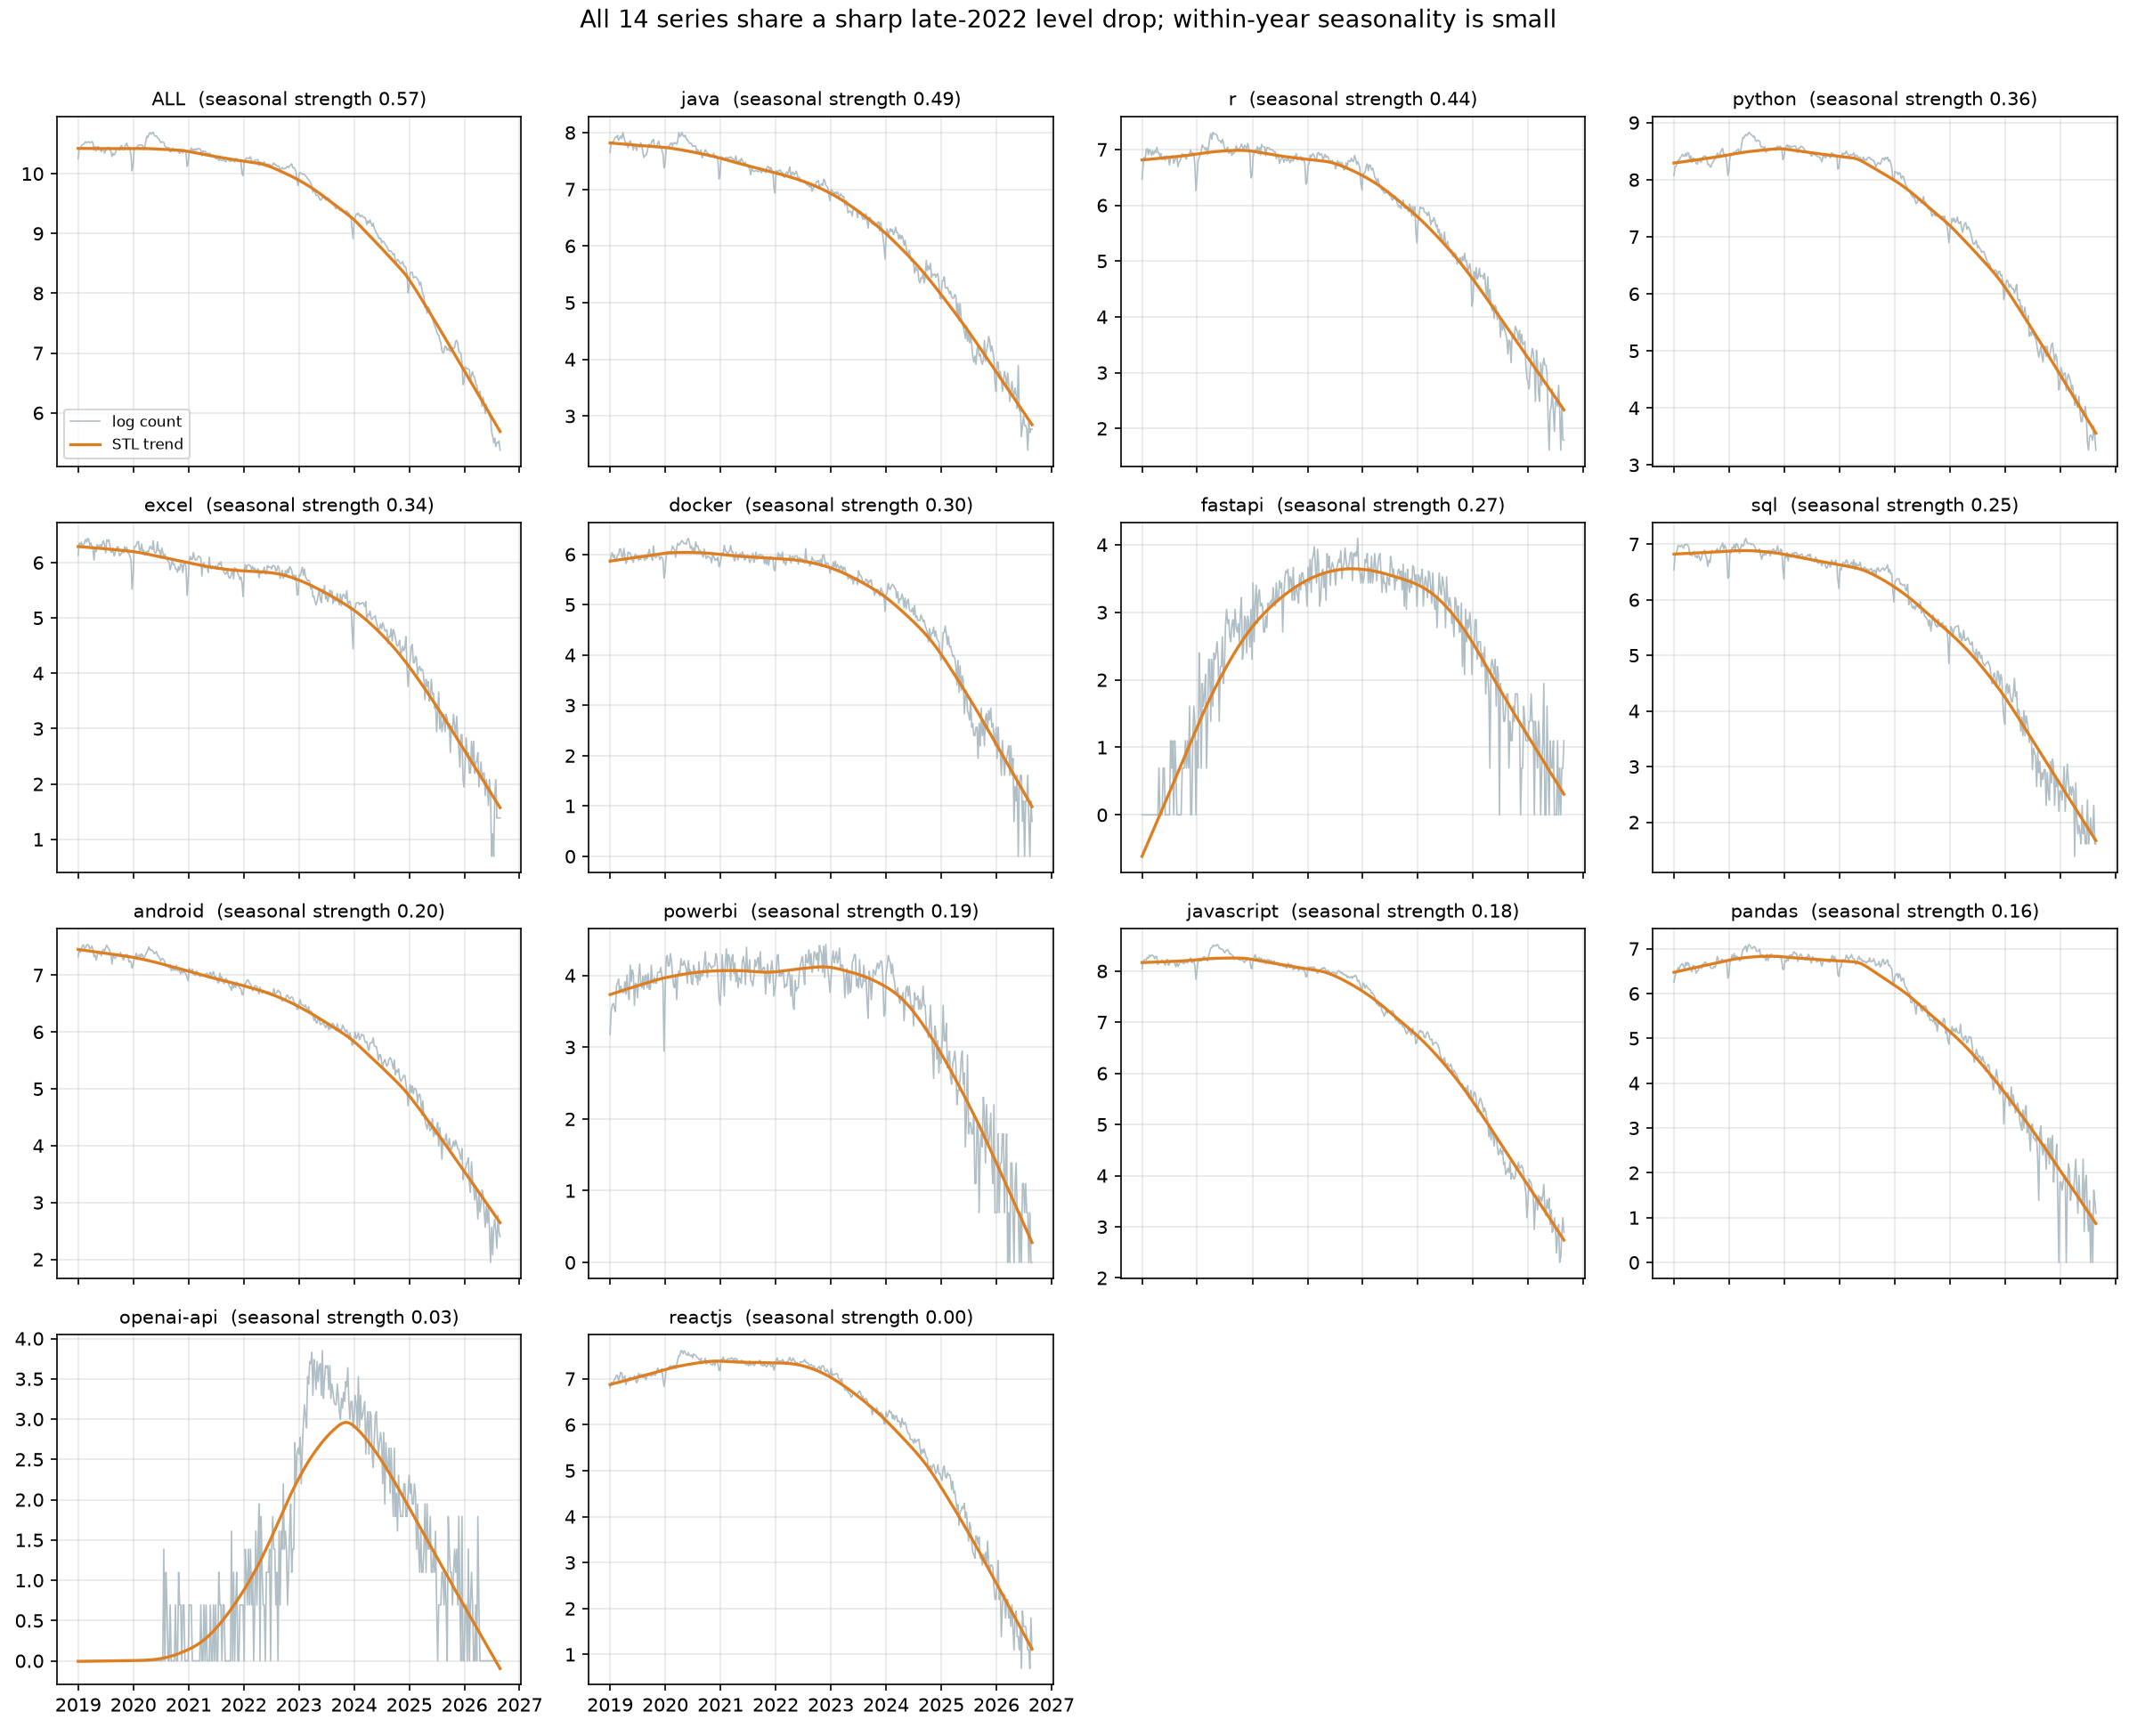

{'model': 'statsmodels STL, robust=True, period=52',
 'input': 'log1p weekly counts (series_long.csv log_count)',
 'series': 14,
 'weeks_per_series': 400,
 'component_identity': 'trend + seasonal + resid = log_count (additive)',
 'seasonal_strength': 'max(0, 1 - Var(resid) / Var(seasonal + resid))',
 'trend_strength': 'max(0, 1 - Var(resid) / Var(trend + resid))',
 'dip_definition': 'lowest mean seasonal phase expanded cyclically over negative phases; months approximate, origin 2019-01-01',
 'interpretation': 'descriptive; seasonality is small relative to the 2022 level change, association is not causation'}

In [3]:
display(pd.read_csv(TS/'stl_summary.csv'))
comp=pd.read_csv(TS/'stl_components.csv')
display(comp[comp.tag.eq('ALL')].head())
display(Image(filename=str(TS/'stl_small_multiples.png')))
display(json.loads((TS/'stl_manifest.json').read_text()))


### Takeaways

- Trend dominates every series (trend strength 0.86–1.00); seasonal strength is minor, from 0.00 for `reactjs` to 0.57 for `ALL`.
- Most tags dip in the late-December/January holiday weeks; `java` and `openai-api` are the exceptions, dipping in late summer/autumn.
- Within-year seasonality is small next to the late-2022 level drop, so the trend is more significant than the seasonality.


### Stationarity: ADF and KPSS (M3-21)

ADF and KPSS on the log level and the first difference for every series. Levels are non-stationary, which justifies differencing once (d = 1);

In [4]:
display(pd.read_csv(TS/'stationarity_decision.csv'))
display(pd.read_csv(TS/'stationarity.csv'))
display(json.loads((TS/'stationarity_manifest.json').read_text()))


,tag,adf_level_p,kpss_level_p,adf_diff_p,kpss_diff_p,level_verdict,diff_verdict,differencing_decision,rationale
0,ALL,1.000000,0.01,2.334794e-29,0.010000,non-stationary,conflicting evidence,d=1,ADF cannot reject a unit root and KPSS rejects...
1,android,1.000000,0.01,7.197399e-03,0.010000,non-stationary,conflicting evidence,d=1,ADF cannot reject a unit root and KPSS rejects...
2,docker,1.000000,0.01,3.150275e-28,0.010000,non-stationary,conflicting evidence,d=1,ADF cannot reject a unit root and KPSS rejects...
3,excel,1.000000,0.01,1.639740e-29,0.049895,non-stationary,conflicting evidence,d=1,ADF cannot reject a unit root and KPSS rejects...
4,fastapi,0.617164,0.01,4.602235e-03,0.049281,non-stationary,conflicting evidence,d=1,ADF cannot reject a unit root and KPSS rejects...
5,java,1.000000,0.01,2.130813e-08,0.010000,non-stationary,conflicting evidence,d=1,ADF cannot reject a unit root and KPSS rejects...
6,javascript,1.000000,0.01,3.135978e-04,0.010000,non-stationary,conflicting evidence,d=1,ADF cannot reject a unit root and KPSS rejects...
7,openai-api,0.611627,0.01,3.237836e-03,0.100000,non-stationary,stationary,d=1,ADF cannot reject a unit root and KPSS rejects...
8,pandas,1.000000,0.01,4.671155e-13,0.014519,non-stationary,conflicting evidence,d=1,ADF cannot reject a unit root and KPSS rejects...
9,powerbi,1.000000,0.01,9.465778e-20,0.014054,non-stationary,conflicting evidence,d=1,ADF cannot reject a unit root and KPSS rejects...


,tag,series,test,null_hypothesis,statistic,p_value,lags,n_obs,crit_1pct,crit_5pct,crit_10pct,reject_5pct,note
0,ALL,level,ADF,unit root (non-stationary),5.263689,1.000000e+00,6,393,-3.447099,-2.868923,-2.570703,False,reject favours stationarity
1,ALL,level,KPSS,stationary,2.649074,1.000000e-02,12,400,0.739000,0.463000,0.347000,True,reject favours non-stationarity; The test stat...
2,ALL,first_difference,ADF,unit root (non-stationary),-16.460043,2.334794e-29,1,397,-3.446930,-2.868848,-2.570663,True,reject favours stationarity
3,ALL,first_difference,KPSS,stationary,1.707478,1.000000e-02,11,399,0.739000,0.463000,0.347000,True,reject favours non-stationarity; The test stat...
4,android,level,ADF,unit root (non-stationary),5.408370,1.000000e+00,13,386,-3.447405,-2.869057,-2.570774,False,reject favours stationarity
5,android,level,KPSS,stationary,2.785980,1.000000e-02,12,400,0.739000,0.463000,0.347000,True,reject favours non-stationarity; The test stat...
6,android,first_difference,ADF,unit root (non-stationary),-3.532210,7.197399e-03,15,383,-3.447540,-2.869116,-2.570806,True,reject favours stationarity
7,android,first_difference,KPSS,stationary,1.091223,1.000000e-02,9,399,0.739000,0.463000,0.347000,True,reject favours non-stationarity; The test stat...
8,docker,level,ADF,unit root (non-stationary),3.823127,1.000000e+00,4,395,-3.447014,-2.868885,-2.570683,False,reject favours stationarity
9,docker,level,KPSS,stationary,2.541690,1.000000e-02,11,400,0.739000,0.463000,0.347000,True,reject favours non-stationarity; The test stat...


{'adf': 'adfuller, regression=c, autolag=AIC; null = unit root',
 'kpss': 'kpss, regression=c, nlags=auto; null = level stationary',
 'transformations': 'level = log1p weekly count; first_difference = level.diff()',
 'significance': 0.05,
 'verdict_rule': 'stationary if ADF rejects and KPSS does not; non-stationary if ADF does not reject and KPSS rejects; else conflicting',
 'decision_rule': 'd=0 on a stationary level; d=1 on a non-stationary level; conflicting levels use the first difference and the ADF level result, labelled ambiguous',
 'series': 14,
 'rows': 56,
 'interpretation': 'decisions support the fixed d=1 used by the M5 SARIMAX backtest; conflicting cases are reported, not hidden'}

### Takeaways

- All 14 log levels are non-stationary (ADF cannot reject, KPSS rejects), which justifies differencing once (`d = 1`).
- First differences are ADF-stationary for every series, but KPSS still rejects for 12, so the two tests conflict; only `openai-api` and `reactjs` agree.

### Change points: ruptures PELT (M3-22)

PELT on each log series with the penalty fixed in advance (BIC). Detected break dates are listed next to the dated events in `docs/event_list.csv`; proximity to an event is association, not causation.

,tag,n_changepoints,model,min_size,penalty,n_within_4_weeks_of_event,changepoint_dates
0,ALL,12,l2,26,0.028648,0,2019-07-30;2020-02-04;2020-08-04;2021-06-22;20...
1,android,12,l2,26,0.103474,0,2019-08-06;2020-08-04;2021-07-06;2022-02-22;20...
2,docker,9,l2,26,0.399344,0,2020-02-18;2020-08-25;2022-07-26;2023-04-04;20...
3,excel,9,l2,26,0.248935,0,2019-08-06;2020-08-18;2021-08-24;2023-03-21;20...
4,fastapi,9,l2,26,1.477252,0,2019-07-09;2020-01-14;2020-07-14;2021-01-19;20...
5,java,12,l2,26,0.105120,1,2019-07-30;2020-01-28;2020-07-28;2021-06-22;20...
6,javascript,11,l2,26,0.092522,0,2020-03-17;2020-09-15;2021-06-01;2021-12-07;20...
7,openai-api,7,l2,26,1.666562,1,2020-07-21;2022-01-11;2022-12-06;2024-02-27;20...
8,pandas,9,l2,26,0.626995,0,2020-01-21;2020-08-18;2022-09-27;2023-03-28;20...
9,powerbi,5,l2,26,0.743964,0,2020-01-07;2024-03-05;2024-10-29;2025-06-10;20...


,tag,index,week_start,mean_before,mean_after,delta,nearest_event_date,nearest_event_name,distance_days,within_4_weeks_of_event
56,java,185,2022-07-19,7.237318,7.008296,-0.229022,2022-06-21,GitHub Copilot GA,28,True
76,openai-api,205,2022-12-06,1.118310,3.241704,2.123394,2022-12-05,Stack Overflow ChatGPT Ban,1,True
108,r,203,2022-11-22,6.804655,6.545354,-0.259302,2022-11-30,ChatGPT Launch,8,True
109,r,229,2023-05-23,6.545354,6.076441,-0.468912,2023-06-05,Stack Overflow Moderator Strike,13,True
127,sql,207,2022-12-20,6.583883,6.105698,-0.478185,2022-12-05,Stack Overflow ChatGPT Ban,15,True
128,sql,233,2023-06-20,6.105698,5.619723,-0.485975,2023-06-05,Stack Overflow Moderator Strike,15,True


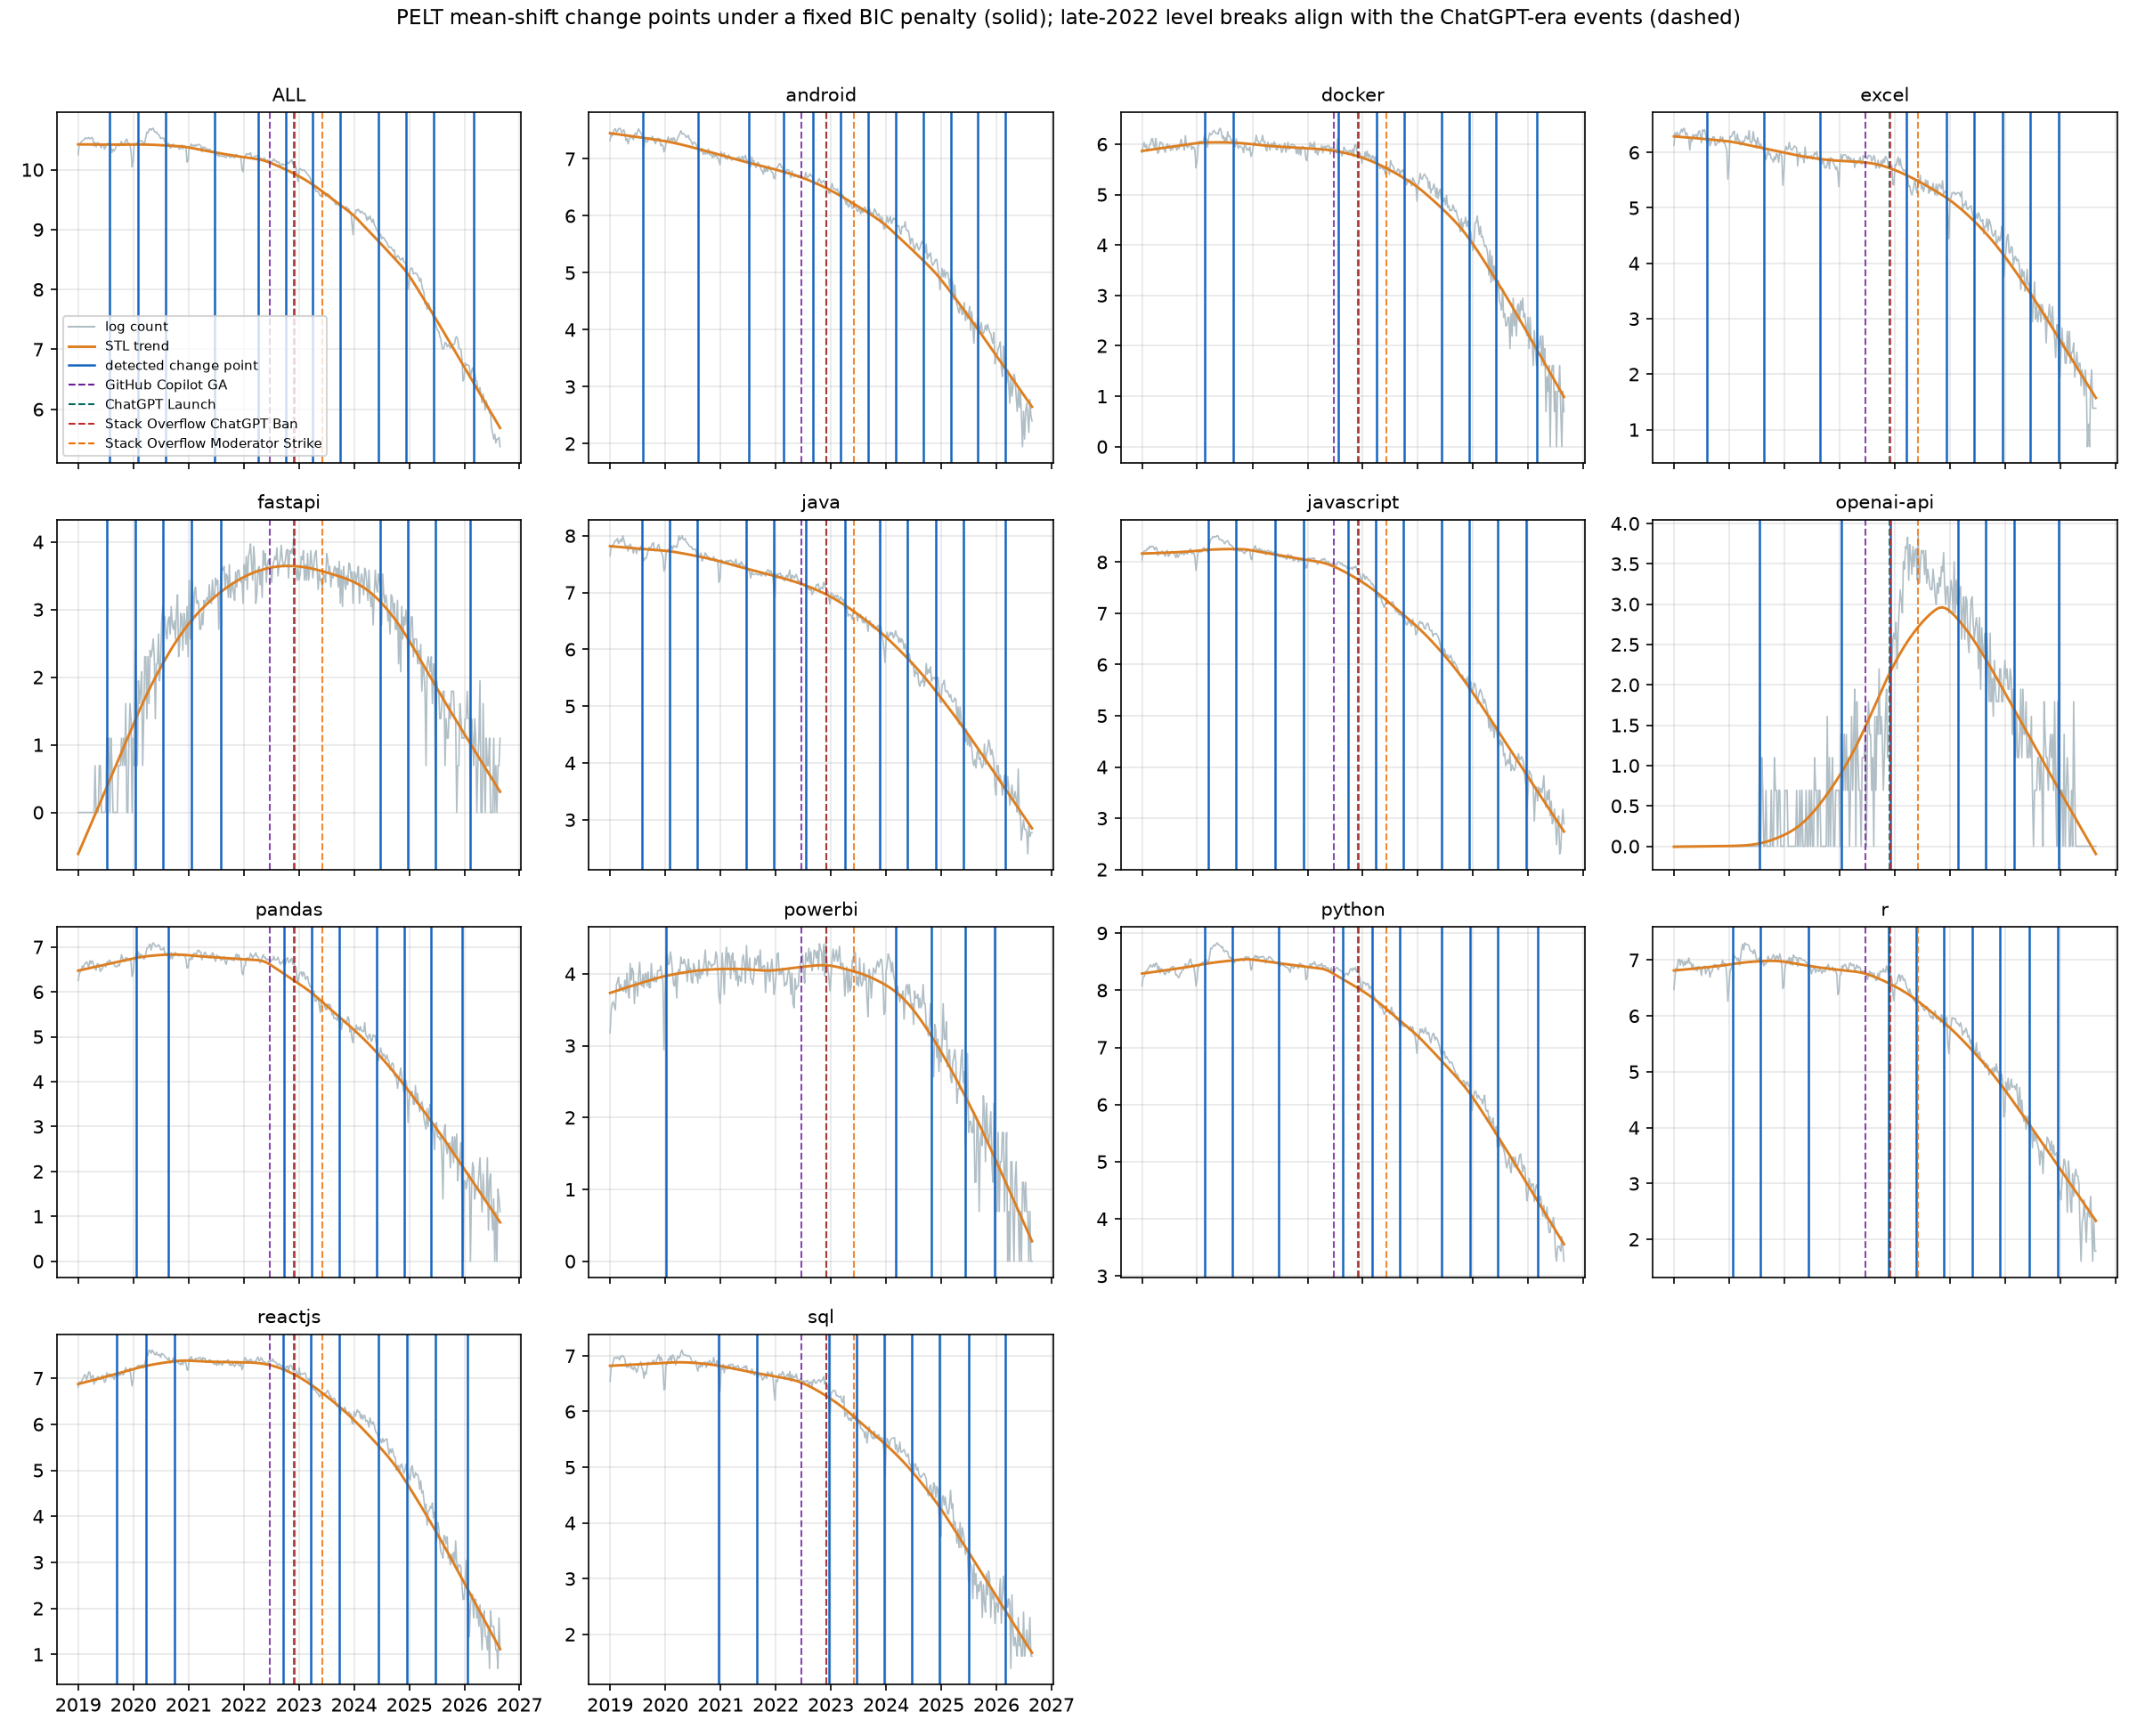

{'method': 'ruptures Pelt, model=l2 (least-squares mean shift), jump=1',
 'min_size': 26,
 'penalty_rule': 'BIC for one extra mean parameter per break: pen = 2*sigma^2*log(n) on the l2 (sum of squares) cost; sigma^2 = Var(first difference)/2, so pen = BIC_PENALTY * Var(first difference) * log(n)',
 'penalty_fixed_in_advance': True,
 'input': 'log1p weekly counts (series_long.csv log_count)',
 'events': 'docs/event_list.csv; every change point carries its nearest event and distance in days',
 'proximity_rule': 'within_4_weeks_of_event = distance_days <= 28',
 'series': 14,
 'change_points': 134,
 'aligned': 'change points within 28 days of an event: 6 of 134; 4 of 14 series have a Nov-Dec 2022 break',
 'interpretation': 'BIC often flags several level shifts on these trending series; a change point within ~4 weeks of the Nov-Dec 2022 events appears in most series, while a few tags (excel, fastapi, powerbi) show no event-near break. Proximity to a dated event is association, not causation

In [5]:
cp=pd.read_csv(TS/'changepoints.csv')
display(pd.read_csv(TS/'changepoints_summary.csv'))
display(cp[cp.within_4_weeks_of_event])
display(Image(filename=str(TS/'changepoints_small_multiples.png')))
display(json.loads((TS/'changepoints_manifest.json').read_text()))


### Takeaways

- With the penalty fixed in advance (BIC), PELT finds 134 breaks across the 14 series (5–12 each) — these trending series carry many level shifts.
- 6 of 134 breaks fall within four weeks of a dated event, across 4 series (`java`, `r`, `openai-api`, `sql`); of these, `r`, `openai-api` and `sql` sit within four weeks of the November–December 2022 events.
- `java`'s event-near break aligns with the GitHub Copilot GA date, not the 2022 ChatGPT events. Proximity to a dated event is association, not causation.


### Interrupted time series (M3-23)

Segmented regression with Newey-West (HAC, lag 4) errors and Fourier seasonality. The level change is `exp(b2) - 1` and the weekly slope change is `exp(b3) - 1`, each with a 95% interval, alongside a 2021-11-30 placebo.

,tag,level_change,level_p,slope_change,slope_ci_lo,slope_ci_hi,slope_p,placebo_slope_change,effect_exceeds_placebo,status
0,ALL,0.370898,4.219204e-04,-0.020500,-0.022117,-0.018881,1.033572e-81,-0.017268,True,significant post-slope decline
1,android,0.468201,5.174867e-05,-0.016009,-0.017788,-0.014226,3.298613e-51,-0.012755,True,significant post-slope decline
2,docker,0.919936,3.630299e-06,-0.025290,-0.027784,-0.022790,2.306435e-60,-0.020123,True,significant post-slope decline
3,excel,0.777316,1.633575e-06,-0.019227,-0.021307,-0.017143,3.761688e-53,-0.014080,True,significant post-slope decline
4,fastapi,-0.224024,1.233298e-01,-0.038866,-0.041653,-0.036071,8.296762e-91,-0.040493,False,significant post-slope decline
5,java,0.301555,2.871667e-04,-0.017390,-0.018722,-0.016055,6.628082e-85,-0.014753,True,significant post-slope decline
6,javascript,0.159170,6.105730e-02,-0.024589,-0.025906,-0.023270,3.957482e-127,-0.021928,True,significant post-slope decline
7,openai-api,16.449082,8.718794e-38,-0.025592,-0.028438,-0.022737,9.357078e-51,-0.008628,True,significant post-slope decline
8,pandas,-0.033097,6.630839e-01,-0.028992,-0.030361,-0.027621,7.958202e-144,-0.026538,True,significant post-slope decline
9,powerbi,1.075858,1.816299e-07,-0.021772,-0.024089,-0.019449,2.694211e-54,-0.016822,True,significant post-slope decline


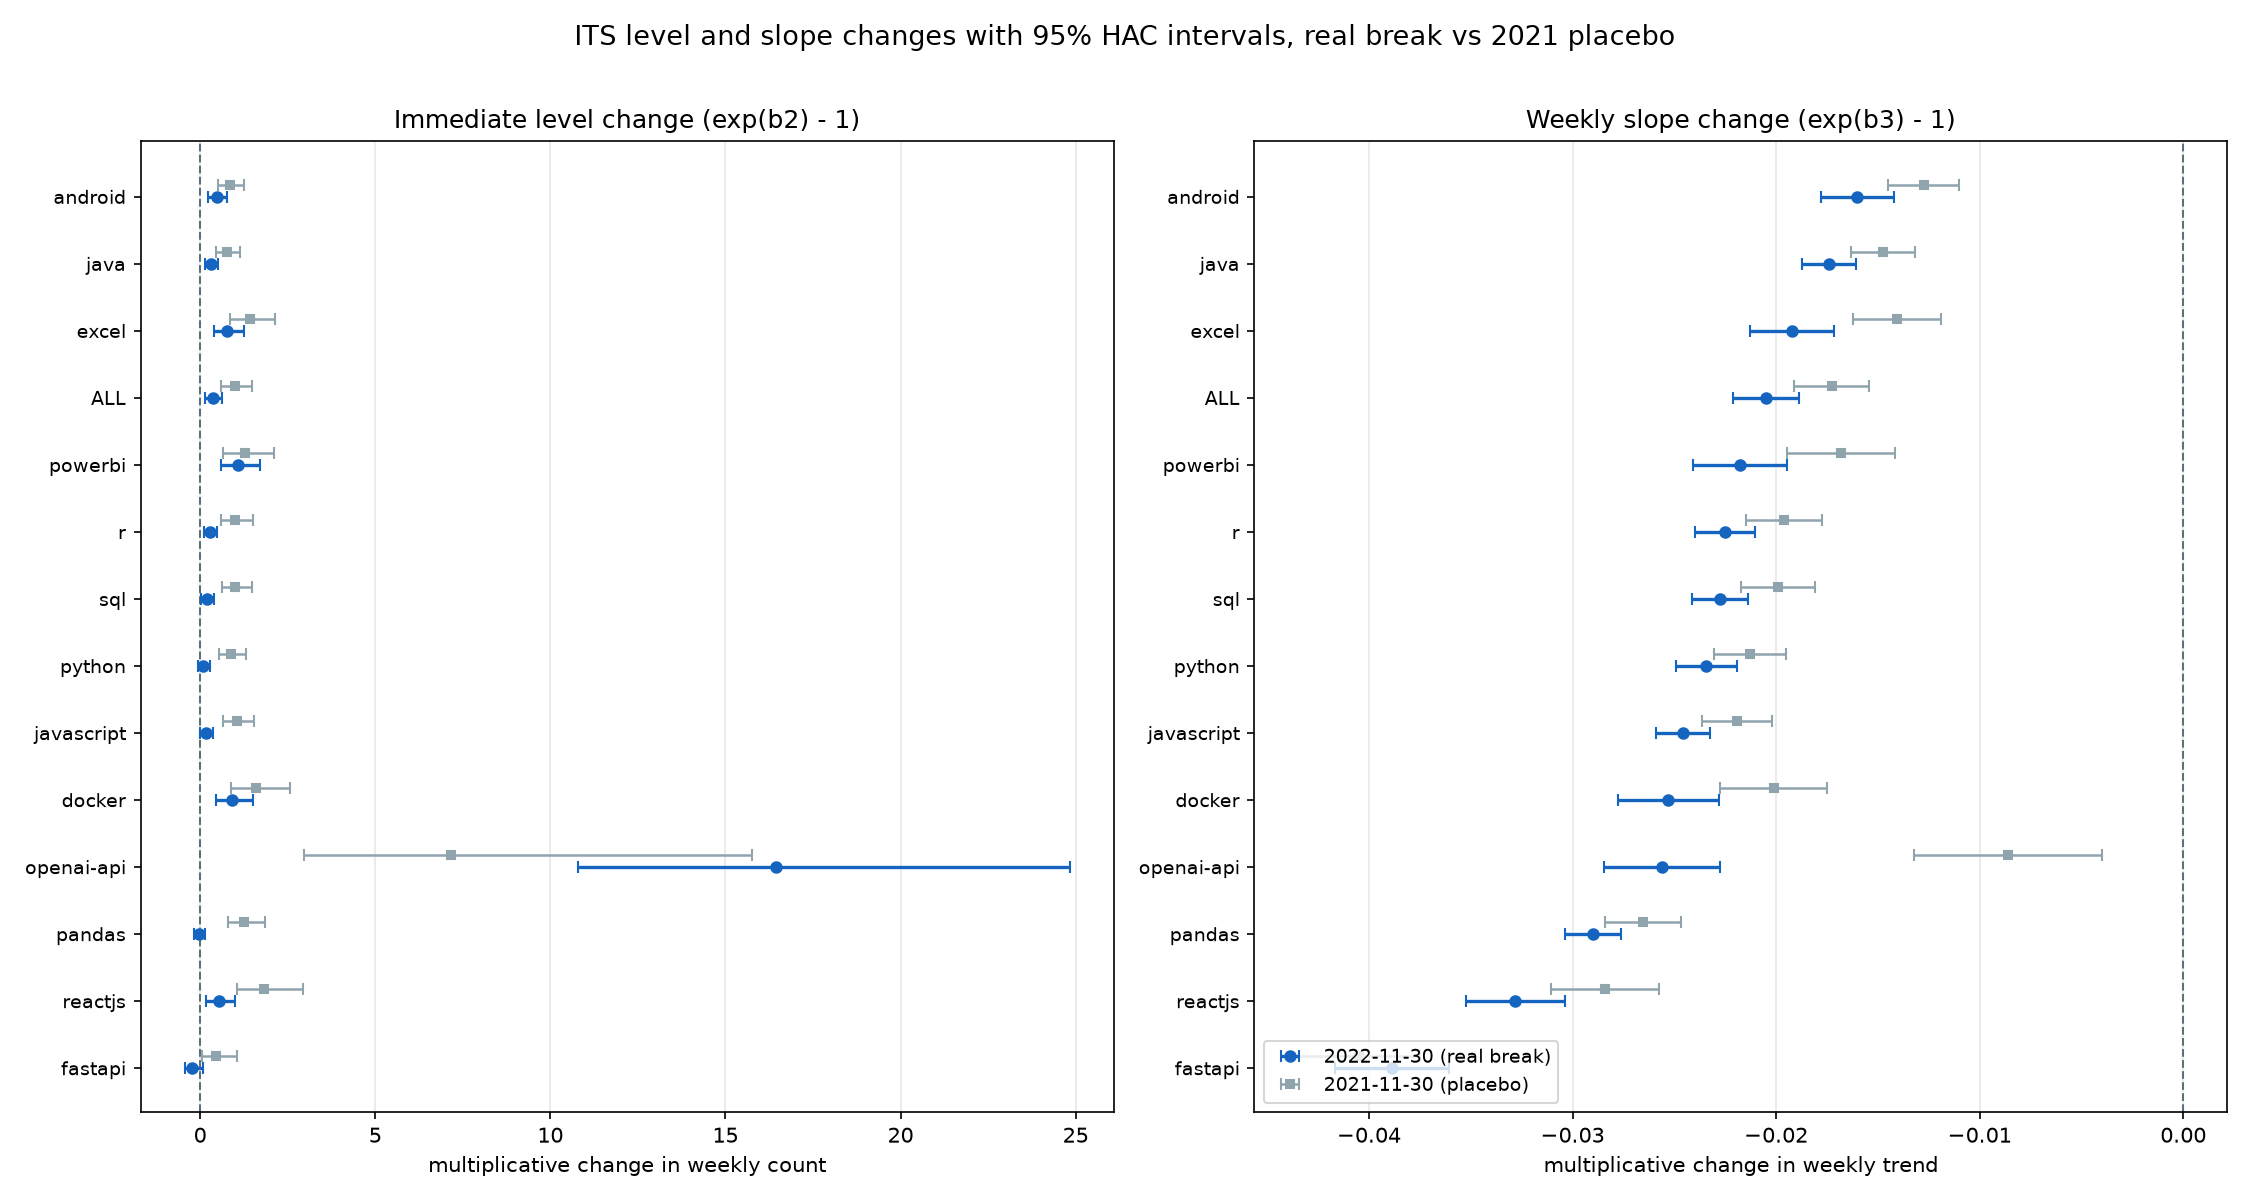

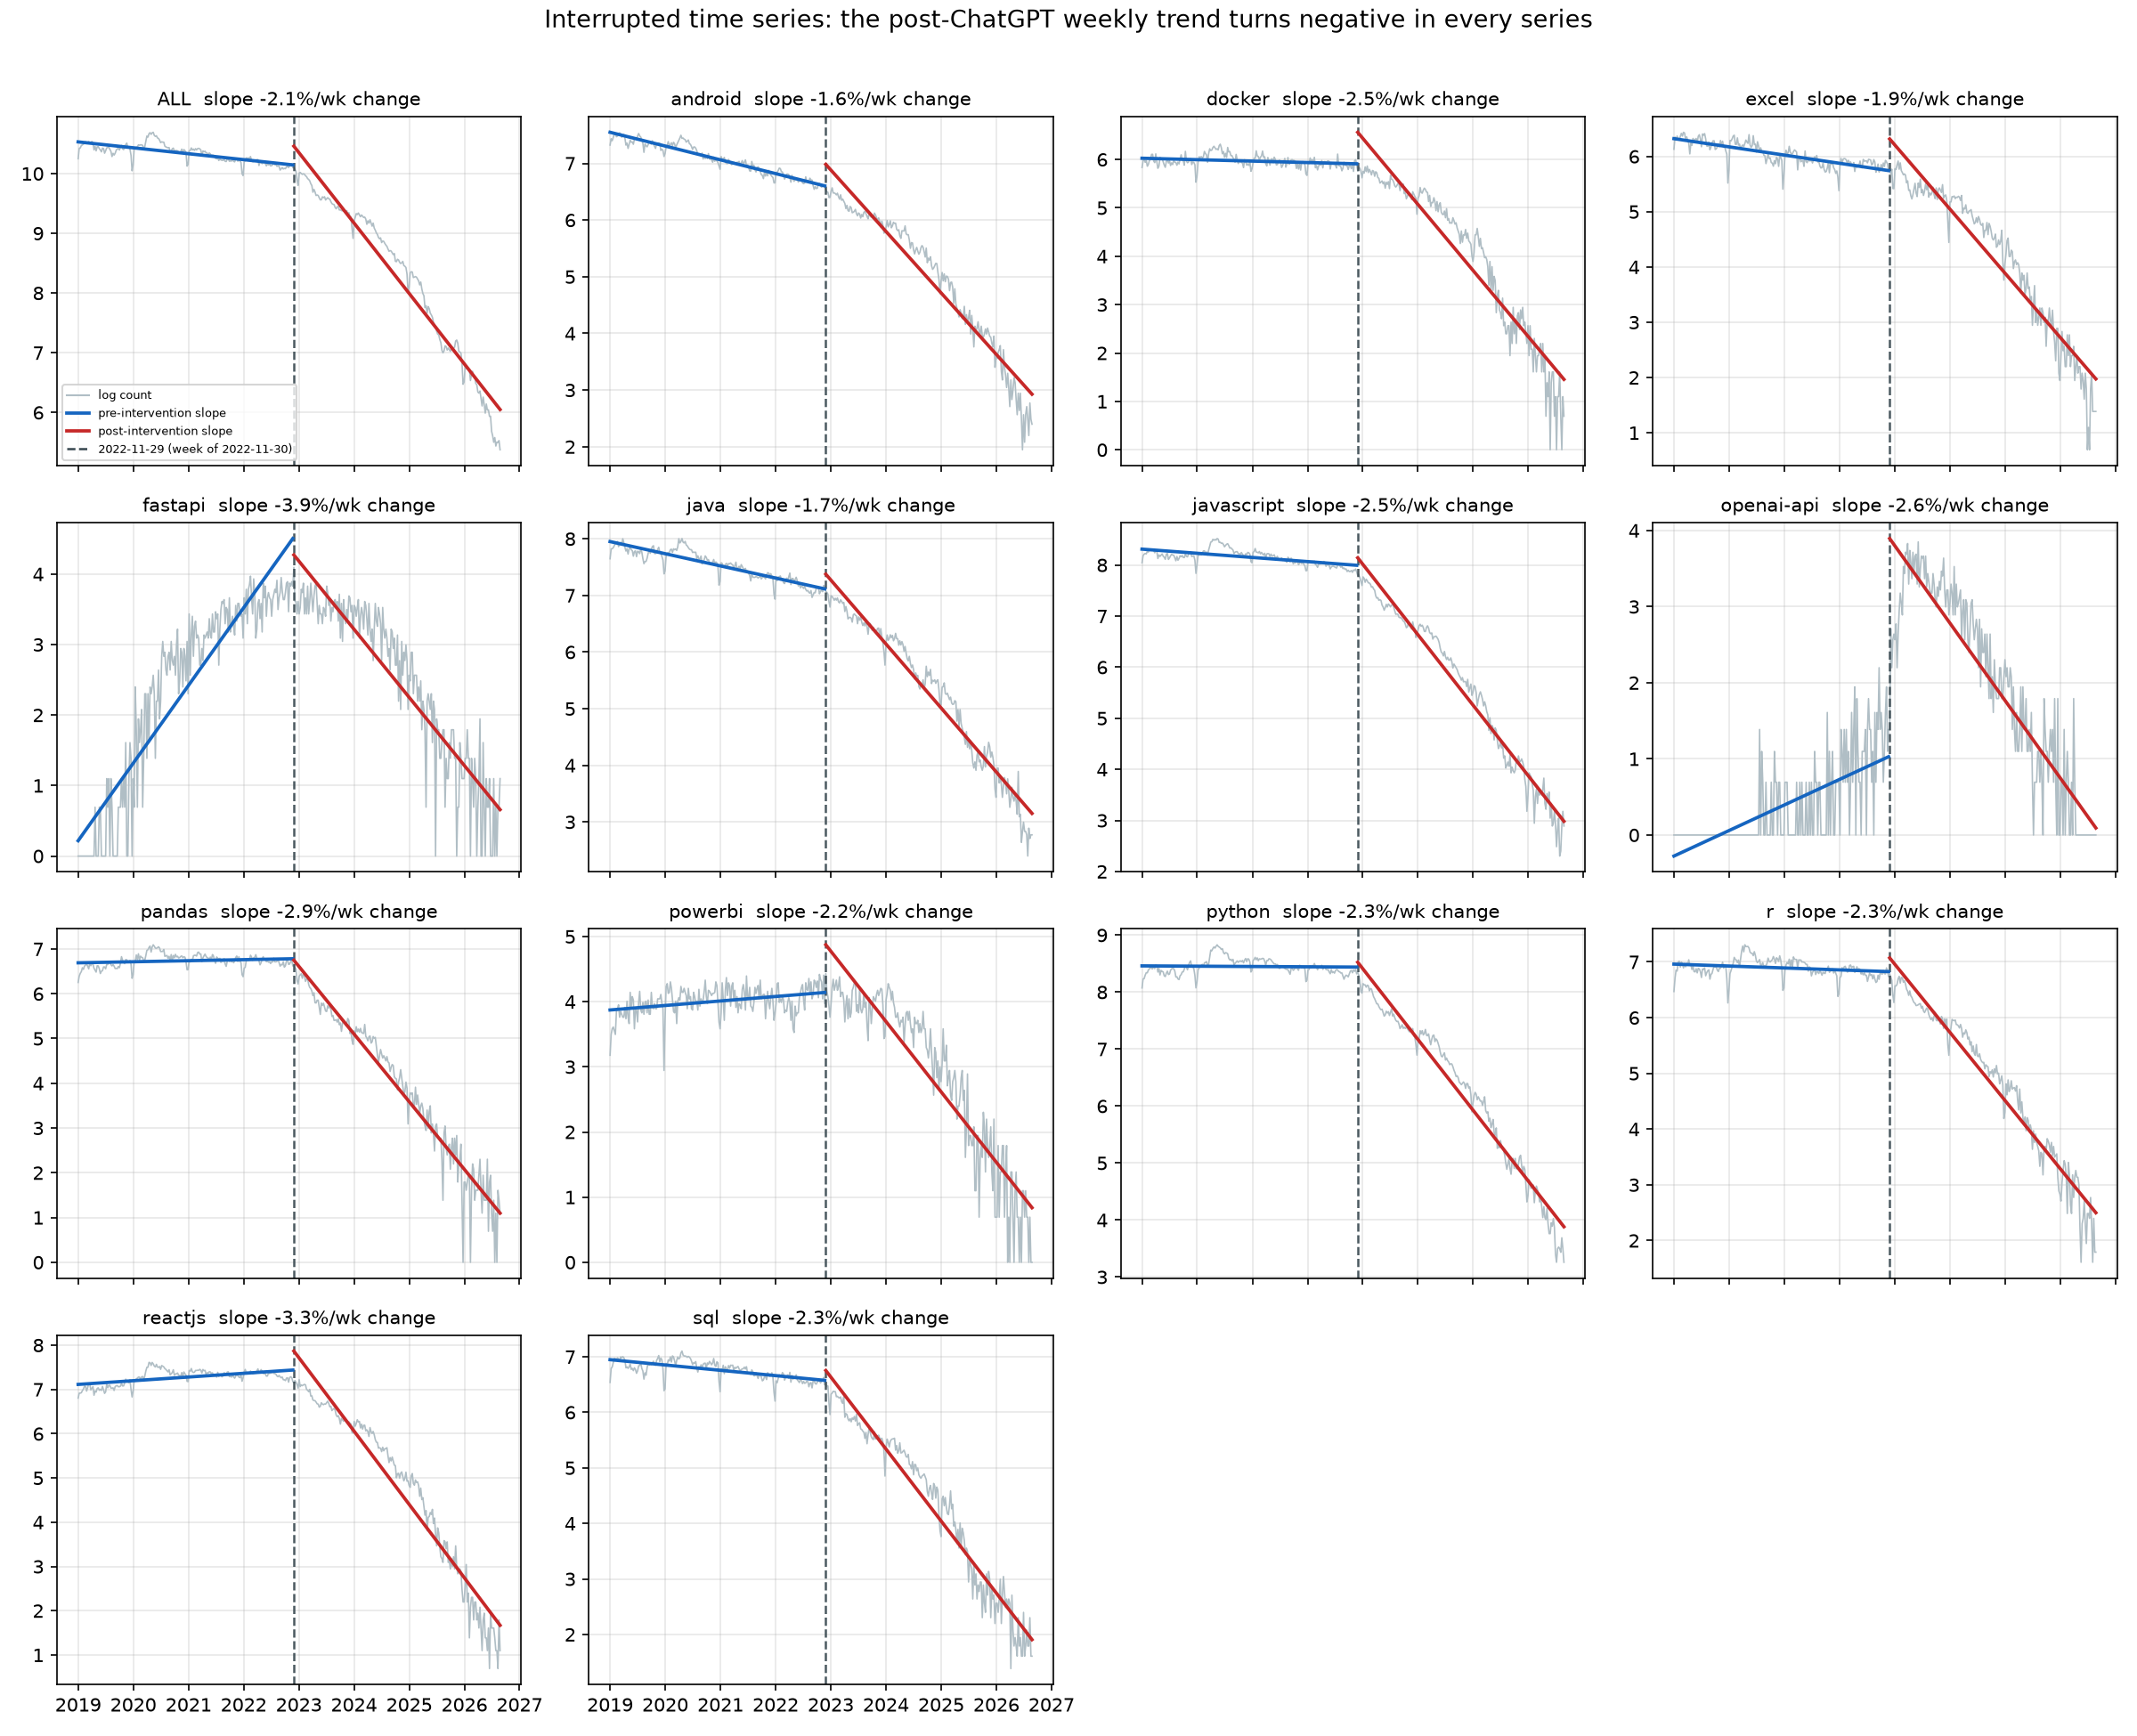

{'model': 'segmented regression: log_count ~ week + post + (week - t0)*post + sin/cos(2*pi*k*week/52.18), k=1,2',
 't0': '2022-11-30 (Tuesday-start week 2022-11-29; one week before the 2022-12-05 ban; mirrors the M5 SARIMAX intervention)',
 'placebo': 'break at 2021-11-30 with the same model; the real effect should be larger',
 'estimator': 'OLS with Newey-West HAC standard errors, lag 4, t-based tests',
 'level_change': 'exp(beta2) - 1: immediate multiplicative change in weekly count at 2022-11-30',
 'slope_change': 'exp(beta3) - 1: weekly slope change after 2022-11-30 on the multiplicative scale, with 95% CI',
 'slope_pre_post': 'exp(beta1) - 1 and exp(beta1 + beta3) - 1 are the pre and post weekly growth rates',
 'status_rule': 'status is significant when the slope-change 95% CI excludes 0; direction follows the sign of beta3',
 'significance': 0.05,
 'series': 14,
 'interpretation': 'the real break should be larger than the placebo; an immediate level change does not imply a sustai

In [6]:
its=pd.read_csv(TS/'its_results.csv')
display(its[['tag','level_change','level_p','slope_change','slope_ci_lo','slope_ci_hi','slope_p','placebo_slope_change','effect_exceeds_placebo','status']])
display(Image(filename=str(TS/'its_forest.png')))
display(Image(filename=str(TS/'its_small_multiples.png')))
display(json.loads((TS/'its_manifest.json').read_text()))


### Takeaways

- Every series shows a significant negative change in weekly slope after 2022-11-30 (95% CI excludes 0); the slope change is −1.6% to −3.9% per week.
- The real break is larger than the 2021-11-30 placebo in 13 of 14 series; `fastapi` is the exception, so its decline should be read with caution.
- Immediate level changes are significant for 10 series, most dramatically `openai-api` (+1645%), but a level jump alone does not imply a lasting slope change.


## Part B — Complete weekly series and fixed evaluation design

In [7]:
TS = ROOT/'reports/review2/ts'
status=json.loads((TS/'run_status.json').read_text())
assert status['status']=='complete'
series=pd.read_csv(TS/'series_long.csv')
display(series.groupby('tag').size().rename('weeks').to_frame())
display(json.loads((TS/'series_manifest.json').read_text()))

,weeks
tag,
ALL,400
android,400
docker,400
excel,400
fastapi,400
java,400
javascript,400
openai-api,400
pandas,400


{'weeks': 400,
 'series': 14,
 'missing_weeks': 0,
 'origin_convention': 'first forecast week; training dates < origin',
 'monthly_rates': 'monthly_rates_masked.csv; never presented as weekly measurements',
 'tag_change': '100 * (forecast at week 26 / last observed weekly count - 1)',
 'interval_point': 'back-transformed median forecast, not arithmetic mean',
 'tag_classes': '< -40 steep decline; [-40,-10] declining; > -10 stabilising'}

## Training-only model selection
Orders use pre-July-2024 AIC; family selection uses 2024 H2. Backtest winners do not choose the final model.

In [8]:
display(pd.read_csv(TS/'model_choices.csv'))
display(pd.read_csv(TS/'validation_metrics.csv').head(20))

,tag,selected_model,p,q,validation_end,selection
0,ALL,sarimax,2,1,2024-12-31,lowest mean validation MASE across four horizo...
1,android,sarimax,1,1,2024-12-31,lowest mean validation MASE across four horizo...
2,docker,drift,1,1,2024-12-31,lowest mean validation MASE across four horizo...
3,excel,sarimax,1,1,2024-12-31,lowest mean validation MASE across four horizo...
4,fastapi,sarimax,1,2,2024-12-31,lowest mean validation MASE across four horizo...
5,java,sarimax,2,2,2024-12-31,lowest mean validation MASE across four horizo...
6,javascript,sarimax,2,1,2024-12-31,lowest mean validation MASE across four horizo...
7,openai-api,ets,1,1,2024-12-31,lowest mean validation MASE across four horizo...
8,pandas,sarimax,1,1,2024-12-31,lowest mean validation MASE across four horizo...
9,powerbi,naive,1,1,2024-12-31,lowest mean validation MASE across four horizo...


,tag,model,horizon,n_origins,mase,smape,coverage80,coverage95,naive_mase,log_rmse,skill_vs_naive
0,ALL,drift,1,7,0.249869,3.949045,0.714286,1.0,0.255199,0.051371,0.020886
1,ALL,drift,4,6,0.409521,6.194492,1.000000,1.0,0.548550,0.067193,0.253448
2,ALL,drift,13,4,1.184802,19.269580,1.000000,1.0,1.640632,0.201431,0.277838
3,ALL,drift,26,1,4.003834,75.739376,0.000000,0.0,4.936467,0.796892,0.188927
4,ALL,ets,1,7,0.255187,4.014522,0.714286,1.0,0.255199,0.053575,0.000047
5,ALL,ets,4,6,0.548387,8.286319,1.000000,1.0,0.548550,0.086606,0.000297
6,ALL,ets,13,4,1.640330,25.735275,0.500000,1.0,1.640632,0.264935,0.000184
7,ALL,ets,26,1,4.936111,85.808563,0.000000,0.0,4.936467,0.917246,0.000072
8,ALL,naive,1,7,0.255199,4.014674,0.714286,1.0,0.255199,0.053579,0.000000
9,ALL,naive,4,6,0.548550,8.288709,1.000000,1.0,0.548550,0.086628,0.000000


## Four-horizon backtest with three baselines
MASE uses each origin’s training naive scale. The comparison table uses identical successful origin/horizon cells. Failure records remain visible.

,model,horizon,n_series,mase,smape,log_rmse,skill_vs_naive,coverage80,coverage95
0,drift,1,14,0.218810,37.092532,0.406094,0.004197,0.491002,0.637369
1,drift,4,14,0.249477,37.991488,0.410250,0.044486,0.672216,0.856525
2,drift,13,14,0.387861,53.760766,0.587033,0.136868,0.704248,0.847044
3,drift,26,14,0.564213,74.611581,0.792137,0.222365,0.667347,0.833036
4,ets,1,14,0.189616,34.947434,0.346303,0.110113,0.493012,0.652675
5,ets,4,14,0.232430,38.255310,0.382306,0.093262,0.496178,0.693000
6,ets,13,14,0.387252,57.058210,0.573650,0.145557,0.413644,0.641518
7,ets,26,14,0.584449,77.056023,0.794480,0.212090,0.338435,0.596726
8,naive,1,14,0.219237,37.059830,0.405908,0.000000,0.487600,0.627474
9,naive,4,14,0.257885,38.474676,0.418104,0.000000,0.655021,0.852766


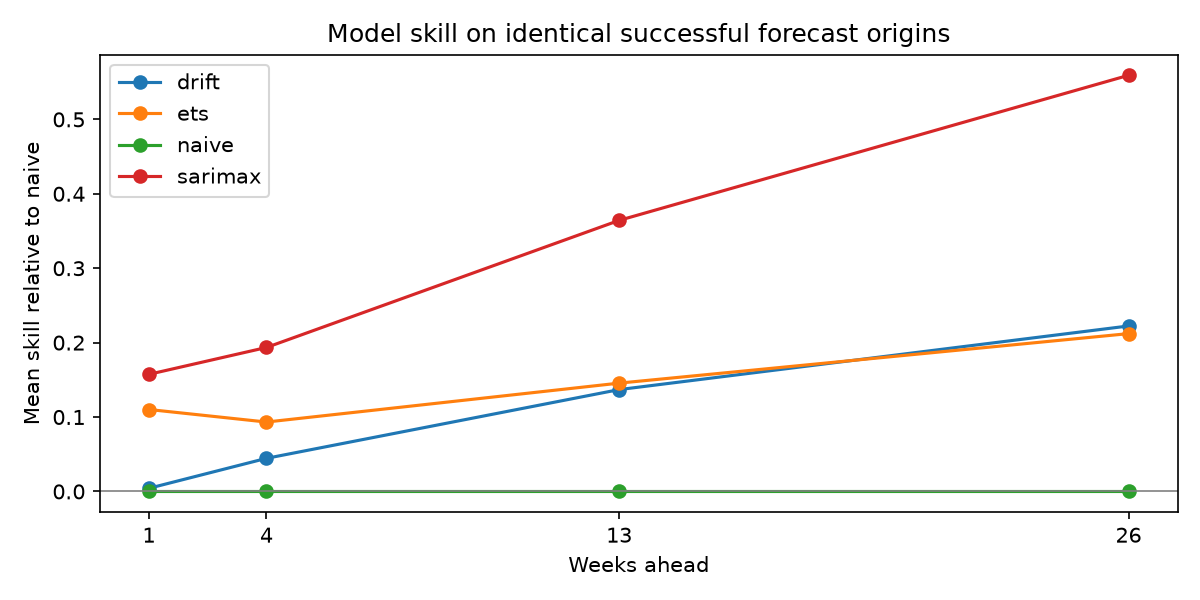

,tag,origin,model,error
0,docker,2024-12-17,sarimax,SARIMAX did not converge
1,java,2025-02-04,sarimax,SARIMAX did not converge
2,java,2025-10-14,sarimax,SARIMAX did not converge
3,javascript,2026-02-03,sarimax,SARIMAX did not converge
4,pandas,2025-09-16,sarimax,SARIMAX did not converge
5,powerbi,2025-03-04,sarimax,SARIMAX did not converge
6,python,2024-11-19,sarimax,SARIMAX did not converge
7,r,2025-07-22,sarimax,SARIMAX did not converge
8,r,2026-05-26,sarimax,SARIMAX did not converge
9,sql,2024-10-22,sarimax,SARIMAX did not converge


In [9]:
summary=pd.read_csv(TS/'backtest_summary_matched.csv')
display(summary)
display(Image(filename=str(TS/'backtest_skill.png')))
display(pd.read_csv(TS/'fit_failures.csv'))

## Statistical and residual checks
DM is a paired scaled-error comparison with HAC adjustment; results are exploratory on short overlapping horizons.

,tag,horizon,model,n,hac_lags,mean_loss_difference,statistic,p_value,loss,note
0,ALL,4,sarimax,21,0,-0.061834,-2.192647,0.040328,absolute count error / training naive scale,negative difference favours selected model; sm...
1,ALL,13,sarimax,19,3,-0.292556,-3.299749,0.003984,absolute count error / training naive scale,negative difference favours selected model; sm...
2,android,4,sarimax,21,0,-0.001032,-0.045222,0.964379,absolute count error / training naive scale,negative difference favours selected model; sm...
3,android,13,sarimax,19,3,-0.152198,-6.600920,0.000003,absolute count error / training naive scale,negative difference favours selected model; sm...
4,docker,4,drift,21,0,-0.012545,-2.055546,0.053118,absolute count error / training naive scale,negative difference favours selected model; sm...
5,docker,13,drift,19,3,-0.060340,-2.839268,0.010880,absolute count error / training naive scale,negative difference favours selected model; sm...
6,excel,4,sarimax,21,0,-0.028544,-1.089201,0.289016,absolute count error / training naive scale,negative difference favours selected model; sm...
7,excel,13,sarimax,19,3,-0.086314,-2.807052,0.011659,absolute count error / training naive scale,negative difference favours selected model; sm...
8,fastapi,4,sarimax,21,0,0.017165,0.276894,0.784703,absolute count error / training naive scale,negative difference favours selected model; sm...
9,fastapi,13,sarimax,19,3,-0.090580,-1.854142,0.080179,absolute count error / training naive scale,negative difference favours selected model; sm...


,tag,model,lag,lb_stat,lb_pvalue
0,ALL,sarimax,10,8.653720,5.652514e-01
1,ALL,sarimax,20,19.637850,4.807789e-01
2,android,sarimax,10,14.226747,1.628980e-01
3,android,sarimax,20,31.221753,5.233019e-02
4,docker,drift,10,285.397574,1.889874e-55
5,docker,drift,20,366.693585,1.602983e-65
6,excel,sarimax,10,12.711226,2.402686e-01
7,excel,sarimax,20,25.172063,1.949275e-01
8,fastapi,sarimax,10,17.110676,7.195059e-02
9,fastapi,sarimax,20,27.142745,1.312955e-01


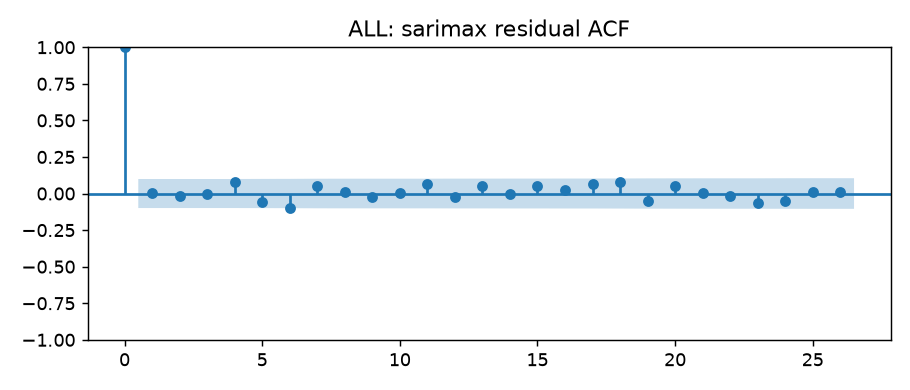

In [10]:
display(pd.read_csv(TS/'diebold_mariano.csv'))
display(pd.read_csv(TS/'residual_checks.csv'))
display(Image(filename=str(TS/'acf_ALL.png')))

## Forecasts through February 2027
Bands are labelled 80/95%; measured coverage may be much lower. The point is a back-transformed log median.

,weeks,last_date
tag,,
ALL,26,2027-02-23
android,26,2027-02-23
docker,26,2027-02-23
excel,26,2027-02-23
fastapi,26,2027-02-23
java,26,2027-02-23
javascript,26,2027-02-23
openai-api,26,2027-02-23
pandas,26,2027-02-23


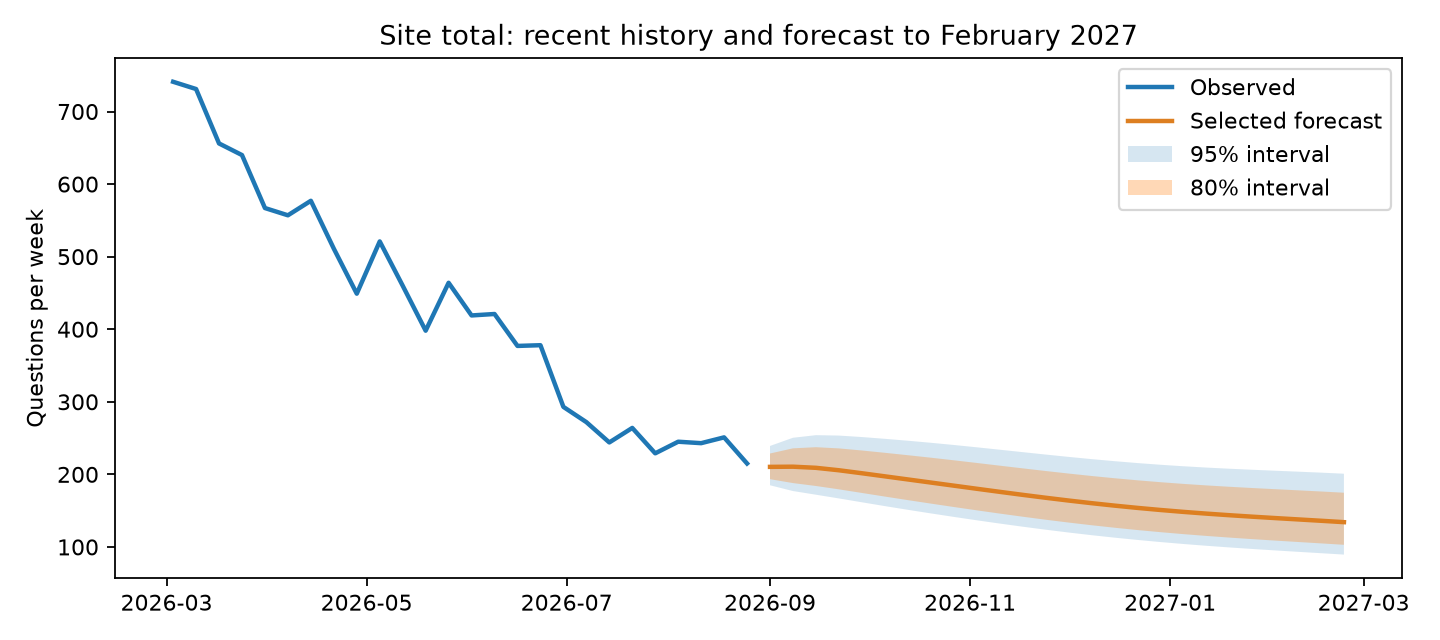

,tag,selected_model,change_26w_pct,forecast_class,last_week_count,forecast_week26,post2023_log_slope,half_life_weeks,load_index_vs_2025,its_slope_change_pct,its_status,its_slope_ci_lo,its_slope_ci_hi,its_slope_p,post2023_share_pct,share_change_pp,share_trend
0,ALL,sarimax,-37.601441,declining,215.0,134.156902,-0.023054,30.066454,8.275674,-2.050,significant post-slope decline,-2.212,-1.888,1.033572e-81,100.000,0.000,site total (100%)
1,android,sarimax,-39.905595,declining,10.0,6.009441,-0.021246,32.624384,9.912092,-1.601,significant post-slope decline,-1.779,-1.423,3.298613e-51,3.703,-0.198,losing relative share
2,docker,drift,-56.938927,steep decline,1.0,0.430611,-0.026917,25.751500,2.246084,-2.529,significant post-slope decline,-2.778,-2.279,2.306435e-60,1.441,0.177,gaining relative share
3,excel,sarimax,-51.482362,steep decline,3.0,1.455529,-0.022823,30.370047,5.625702,-1.923,significant post-slope decline,-2.131,-1.714,3.761688e-53,1.619,0.262,gaining relative share
4,fastapi,sarimax,-94.834287,steep decline,2.0,0.103314,-0.019011,36.460227,2.484432,-3.887,significant post-slope decline,-4.165,-3.607,8.296762e-91,0.280,0.217,gaining relative share
5,java,sarimax,-39.253378,declining,15.0,9.111993,-0.022075,31.399048,11.241094,-1.739,significant post-slope decline,-1.872,-1.606,6.628082e-85,5.011,-1.111,losing relative share
6,javascript,sarimax,-52.451019,steep decline,17.0,8.083327,-0.026787,25.875841,9.612978,-2.459,significant post-slope decline,-2.591,-2.327,3.957482e-127,6.864,-4.409,losing relative share
7,openai-api,ets,NaN,not classifiable: zero baseline,0.0,0.000000,-0.020740,33.420984,0.000000,-2.559,significant post-slope decline,-2.844,-2.274,9.357078e-51,0.153,0.151,gaining relative share
8,pandas,sarimax,-86.692805,steep decline,2.0,0.266144,-0.029112,23.809542,4.022757,-2.899,significant post-slope decline,-3.036,-2.762,7.958202e-144,1.352,-1.399,losing relative share
9,powerbi,naive,NaN,not classifiable: zero baseline,0.0,0.000000,-0.021321,32.509587,0.000000,-2.177,significant post-slope decline,-2.409,-1.945,2.694211e-54,0.422,0.242,gaining relative share


In [11]:
fc=pd.read_csv(TS/'forecasts_26w.csv')
display(fc[fc.selected].groupby('tag').agg(weeks=('horizon','size'),last_date=('week_start','max')))
display(Image(filename=str(TS/'forecast_ALL.png')))
display(pd.read_csv(TS/'tag_classes.csv'))

## Findings, handoff and remaining dependencies

In [12]:
print((ROOT/'reports/review2/m5_findings.md').read_text())
display(json.loads((TS/'dashboard_handoff.json').read_text()))

# Member 5: forecasting findings

- Models were selected on 2024 H2 validation; the expanding-window 2025–26 backtest uses first-forecast-week origins spaced four weeks apart.
- On matched origins, SARIMAX's mean 26-week skill versus naive is 55.9%; this is a retrospective model-family comparison, not a new selection from test results.
- Nominal 95% SARIMAX bands cover 52.0% of the 26-week endpoints on matched origins: intervals are too narrow for this changing process.
- The validation-selected site model is sarimax; its week-26 median is 134.2 questions versus 215 in the last observed week (-37.6%). Forecasts end February 23, 2027.
- There are 10 recorded fit failures. Zero baseline counts cannot support a percentage-change tag class; Interrupted Time Series confirms significant post-AI slope declines across all 14 series (mean slope change -2.3%/wk; emerging AI tooling gained relative share while legacy ecosystems lost share).

Association is not causation. MASE is scaled forecast e

{'owner': 'M5 Adhikkesh',
 'schemas': {'backtest_winners.csv': ['tag',
   'model',
   'horizon',
   'n_origins',
   'mase',
   'smape',
   'coverage80',
   'coverage95',
   'naive_mase',
   'log_rmse',
   'skill_vs_naive'],
  'backtest_metrics_matched.csv': ['tag',
   'model',
   'horizon',
   'n_origins',
   'mase',
   'smape',
   'coverage80',
   'coverage95',
   'naive_mase',
   'log_rmse',
   'skill_vs_naive'],
  'validation_metrics.csv': ['tag',
   'model',
   'horizon',
   'n_origins',
   'mase',
   'smape',
   'coverage80',
   'coverage95',
   'naive_mase',
   'log_rmse',
   'skill_vs_naive'],
  'backtest_metrics.csv': ['tag',
   'model',
   'horizon',
   'n_origins',
   'mase',
   'smape',
   'coverage80',
   'coverage95',
   'naive_mase',
   'log_rmse',
   'skill_vs_naive'],
  'sarimax_aic_grid.csv': ['tag', 'p', 'q', 'aic', 'converged'],
  'backtest_predictions.csv': ['tag',
   'model',
   'origin',
   'training_last_week',
   'target_week',
   'horizon',
   'actual',
   'mas

## Optional appendix
The GRU and classifier what-if page are stretch items and are not represented as completed analyses.